In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import math
import torch.nn.functional as F
from torch.utils.data import Subset
import numpy as np
import pandas as pd
import copy
from torch.utils.data import ConcatDataset
from IPython.display import clear_output

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import math
import torch.nn.functional as F
from torch.utils.data import Subset
import numpy as np
import pandas as pd
import copy
from torch.utils.data import ConcatDataset
from torchvision.datasets import ImageFolder
from torchvision import transforms
from torch.utils.data import DataLoader
import os
from IPython.display import clear_output

In [2]:
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
train_set = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_set = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

In [3]:
X = train_set.data.reshape(-1, 784) / 255
Y = train_set.data[train_set.targets == 8].cpu().unsqueeze(1).reshape(-1, 784) / 255
Y = (Y - 0.5) / 0.5
X = (X - 0.5) / 0.5

X.shape, Y.shape

(torch.Size([60000, 784]), torch.Size([5851, 784]))

In [4]:
img_size = 28
batch_size = 128
epochs = 100
diffusion_steps = timesteps = 500
img_size = 28

beta = torch.linspace(1e-4, 0.02, diffusion_steps)
alpha = 1. - beta
baralphas = alpha_bar = torch.cumprod(alpha, dim=0)

In [5]:
def sample_timesteps(batch_size, diffusion_steps, power=3.0):
    u = torch.rand(batch_size, 1)
    t = (u ** power * diffusion_steps).long()
    return t

def noise(Xbatch, t):
    eps = torch.randn(size=Xbatch.shape)
    noised = (baralphas[t] ** 0.5).repeat(1, Xbatch.shape[1]) * Xbatch + ((1 - baralphas[t]) ** 0.5).repeat(1, Xbatch.shape[1]) * eps
    return noised, eps

rand_timesteps = sample_timesteps(X.shape[0], diffusion_steps)
X, _ = noise(X, rand_timesteps)

rand_timesteps = sample_timesteps(Y.shape[0], diffusion_steps)
Y, _ = noise(Y, rand_timesteps)

In [6]:
n_components = 32

mean_pca = X.mean(dim=0, keepdim=True)
X_centered = X - mean_pca

cov = X_centered.T @ X_centered / (X_centered.shape[0] - 1)

eigvals, eigvecs = torch.linalg.eigh(cov)

idx = torch.argsort(eigvals, descending=True)
eigvecs = eigvecs[:, idx]

components = eigvecs[:, :n_components]

In [7]:
Y_centered = Y - mean_pca

X_pca = X_centered @ components
Y_pca = Y_centered @ components


In [15]:
phi_all = X_pca.cuda()
phi_eight = Y_pca.cuda()

n_de = phi_all.shape[0]
n_nu = phi_eight.shape[0]
reg = 0.01

H = (phi_all.T @ phi_all) / n_de
H += reg * torch.eye(32).to("cuda")

h = torch.mean(phi_eight, dim=0, keepdim=True).T

theta = torch.linalg.solve(H, h)

In [16]:
phi_all.shape

torch.Size([60000, 32])

In [17]:
phi_eight.shape

torch.Size([5851, 32])

In [18]:
class BinaryClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size=3, padding=1),
            nn.GroupNorm(32, 64), nn.ReLU(), nn.MaxPool2d(2),
            
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.GroupNorm(32, 128), nn.ReLU(), nn.MaxPool2d(2),
            
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.GroupNorm(32, 256), nn.ReLU(), nn.MaxPool2d(2),
            
            nn.Conv2d(256, 512, kernel_size=3, padding=1),
            nn.GroupNorm(32, 512), nn.ReLU(), nn.MaxPool2d(2),
            
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten()
        )
        
        self.time_mlp = nn.Sequential(
            nn.Linear(1, 128),
            nn.ReLU(),
            nn.Linear(128, 128)
        )
        
        self.fc = nn.Linear(512 + 128, 2)

    def forward(self, x, t):
        img_feats = self.features(x)
        
        if t.dim() == 1:
            t = t.unsqueeze(-1).float()
            
        time_feats = self.time_mlp(t)
        
        combined = torch.cat([img_feats, time_feats], dim=1)
        return self.fc(combined)


class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels, groups=8):
        super().__init__()
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(groups, out_channels),  # GroupNorm is standard for Diffusion
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(groups, out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.double_conv(x)

class uNet(nn.Module):
    def __init__(self, time_dim=128):
        super().__init__()
        self.time_mlp = nn.Sequential(
            nn.Linear(1, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim)
        )

        self.input = DoubleConv(1, 64)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(64, 128))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(128, 256))

        self.bottleneck = DoubleConv(256, 512)

        self.up1 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.conv_up1 = DoubleConv(384, 256)
        
        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.conv_up2 = DoubleConv(192, 128)

        self.output = nn.Conv2d(128, 1, kernel_size=1)

        self.emb_down1 = nn.Linear(time_dim, 128)
        self.emb_down2 = nn.Linear(time_dim, 256)
        self.emb_up1 = nn.Linear(time_dim, 256)
        self.emb_up2 = nn.Linear(time_dim, 128)

    def forward(self, x, t):
        t = t.view(-1, 1) 
        emb = self.time_mlp(t)
        
        x1 = self.input(x)
        
        x2 = self.down1(x1)
        x2 = x2 + self.emb_down1(emb)[:, :, None, None]
        
        x3 = self.down2(x2)
        x3 = x3 + self.emb_down2(emb)[:, :, None, None]

        x_mid = self.bottleneck(x3)

        x_up1 = self.up1(x_mid)
        x_up1 = torch.cat([x_up1, x2], dim=1)
        x_up1 = self.conv_up1(x_up1) 
        x_up1 = x_up1 + self.emb_up1(emb)[:, :, None, None]
        
        x_up2 = self.up2(x_up1)
        x_up2 = torch.cat([x_up2, x1], dim=1)
        x_up2 = self.conv_up2(x_up2)
        x_up2 = x_up2 + self.emb_up2(emb)[:, :, None, None]

        return self.output(x_up2)

class Classifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 64, 3, padding=1),
            nn.GroupNorm(16, 64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.1),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.GroupNorm(16, 128),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.2),

            nn.Conv2d(128, 256, 3, padding=1),
            nn.GroupNorm(16, 256),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.3),

            nn.AdaptiveAvgPool2d(1),
            nn.Flatten()
        )

        self.fc = nn.Linear(256, 10)

    def forward(self, x):
        x = self.features(x)
        return self.fc(x)

In [19]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
biCls = BinaryClassifier().to(device)
cls = Classifier().to(device)
model = uNet().to(device)

biCls.load_state_dict(torch.load("8_binary_clsf.pth", map_location=device))
cls.load_state_dict(torch.load("mnist_cnn_wei.pth", map_location=device))
model.load_state_dict(torch.load("uncond_diff_wei.pth", map_location=device))

<All keys matched successfully>

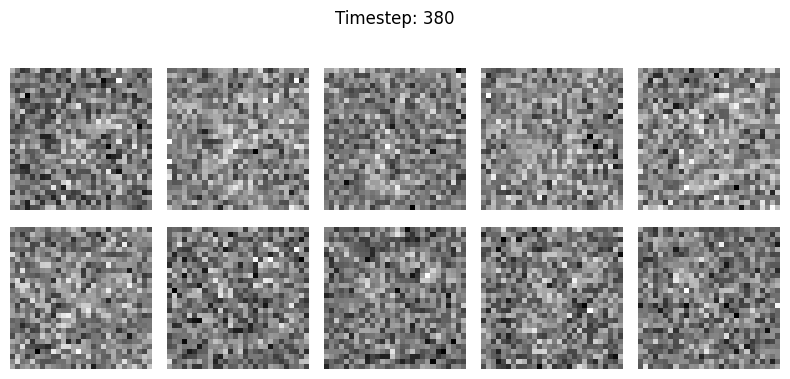

KeyboardInterrupt: 

In [20]:
import matplotlib.pyplot as plt
from IPython.display import clear_output, display


n_samples = 50
s = 15
img_size = 28
device = "cuda"

xt = torch.randn(n_samples, 1, img_size, img_size).to(device)

for i in reversed(range(timesteps)):
    t = torch.tensor([i] * n_samples, device=device)
    t_float = t.float() / timesteps
    
    with torch.no_grad():
        eps_pred = model(xt, t_float)
    
    alpha_t = alpha[i]
    alpha_bar_t = alpha_bar[i]
    beta_t = beta[i]

    mean = (xt - ((1 - alpha_t) / torch.sqrt(1 - alpha_bar_t)) * eps_pred) / torch.sqrt(alpha_t)

    xt_for_grad = xt.detach().requires_grad_(True)

    xt_flat = xt_for_grad.reshape(-1, 784)

    xt_centred = xt_flat - mean_pca.cuda()
    xt_pca = xt_centred @ components.cuda()
    
    ratio = xt_pca @ theta
    log_r = torch.log(torch.clamp(ratio, min=1e-8))
    
    guide_score = torch.autograd.grad(log_r.sum(), xt_for_grad)[0]
    
    mean = mean + s * beta_t * torch.tanh(guide_score)
    
    if i > 0:
        noise = torch.randn_like(xt)
        xt = mean + torch.sqrt(beta_t) * noise
    else:
        xt = mean

    if i % 20 == 0 or i == 0:
        clear_output(wait=True)
    
        imgs = xt[:10].detach().cpu()
    
        fig, axes = plt.subplots(2, 5, figsize=(8, 4))
        axes = axes.flatten()
    
        for j in range(10):
            axes[j].imshow(imgs[j, 0].numpy(), cmap='gray')
            axes[j].axis('off')
    
        plt.suptitle(f"Timestep: {i}")
        plt.tight_layout()
        plt.show()

s: {} complete 0


(-0.5, 223.5, 223.5, -0.5)

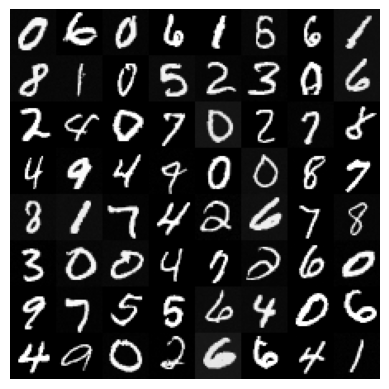

In [12]:
n_samples = 64
s = 0
final = []

xt = torch.randn(n_samples, 1, img_size, img_size).to(device)

for i in reversed(range(timesteps)):
    t = torch.tensor([i] * n_samples, device=device)
    t_float = t.float() / timesteps
    
    with torch.no_grad():
        eps_pred = model(xt, t_float)
    
    alpha_t = alpha[i]
    alpha_bar_t = alpha_bar[i]
    beta_t = beta[i]

    mean = (xt - ((1 - alpha_t) / torch.sqrt(1 - alpha_bar_t)) * eps_pred) / torch.sqrt(alpha_t)

    xt_for_grad = xt.detach().requires_grad_(True)

    xt_flat = xt_for_grad.reshape(-1, 784)

    xt_centred = xt_flat - mean_pca.cuda()
    xt_pca = xt_centred @ components.cuda()
    
    ratio = xt_pca @ theta
    log_r = torch.log(torch.clamp(ratio, min=1e-8))
    
    guide_score = torch.autograd.grad(log_r.sum(), xt_for_grad)[0]
    
    mean = mean + s * beta_t * guide_score
    
    if i > 0:
        noise = torch.randn_like(xt)
        xt = mean + torch.sqrt(beta_t) * noise
    else:
        xt = mean

xt = xt.cpu()
print("s: {} complete", s)

torch.concat([xt[i] for i in range(xt.shape[0])], dim =1).shape

img = torch.tensor([])
for row in xt.split(8):
    img_row = torch.concat([row[i] for i in range(row.shape[0])], dim =1).clamp(-1,1)
    img = torch.cat([img, img_row], dim=-1)

plt.imshow(img[0],cmap="gray")
plt.axis('off')

s: {} complete 15


(-0.5, 223.5, 223.5, -0.5)

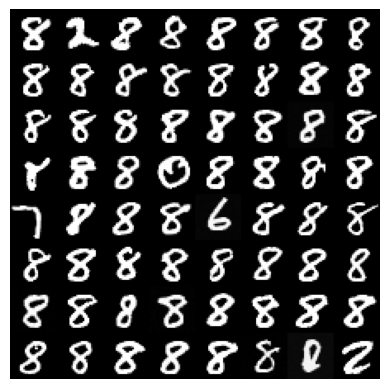

In [14]:
n_samples = 64
s = 15
final = []

xt = torch.randn(n_samples, 1, img_size, img_size).to(device)

for i in reversed(range(timesteps)):
    t = torch.tensor([i] * n_samples, device=device)
    t_float = t.float() / timesteps
    
    with torch.no_grad():
        eps_pred = model(xt, t_float)
    
    alpha_t = alpha[i]
    alpha_bar_t = alpha_bar[i]
    beta_t = beta[i]

    mean = (xt - ((1 - alpha_t) / torch.sqrt(1 - alpha_bar_t)) * eps_pred) / torch.sqrt(alpha_t)

    xt_for_grad = xt.detach().requires_grad_(True)

    xt_flat = xt_for_grad.reshape(-1, 784)

    xt_centred = xt_flat - mean_pca.cuda()
    xt_pca = xt_centred @ components.cuda()
    
    ratio = xt_pca @ theta
    log_r = torch.log(torch.clamp(ratio, min=1e-8))
    
    guide_score = torch.autograd.grad(log_r.sum(), xt_for_grad)[0]
    
    mean = mean + s * beta_t * torch.tanh(guide_score)
    
    if i > 0:
        noise = torch.randn_like(xt)
        xt = mean + torch.sqrt(beta_t) * noise
    else:
        xt = mean

xt = xt.cpu()
print("s: {} complete", s)

torch.concat([xt[i] for i in range(xt.shape[0])], dim =1).shape

img = torch.tensor([])
for row in xt.split(8):
    img_row = torch.concat([row[i] for i in range(row.shape[0])], dim =1).clamp(-1,1)
    img = torch.cat([img, img_row], dim=-1)

plt.imshow(img[0],cmap="gray")
plt.axis('off')

In [32]:
n_samples = 4
s = 20
final = []

xt_hist = []

xt = torch.randn(n_samples, 1, img_size, img_size).to(device)
xt_hist.append(xt)

for i in reversed(range(timesteps)):
    t = torch.tensor([i] * n_samples, device=device)
    t_float = t.float() / timesteps
    
    with torch.no_grad():
        eps_pred = model(xt, t_float)
    
    alpha_t = alpha[i]
    alpha_bar_t = alpha_bar[i]
    beta_t = beta[i]

    mean = (xt - ((1 - alpha_t) / torch.sqrt(1 - alpha_bar_t)) * eps_pred) / torch.sqrt(alpha_t)

    if i in [375, 250, 125]:
        xt_hist.append(xt)

    xt_for_grad = xt.detach().requires_grad_(True)

    xt_flat = xt_for_grad.reshape(-1, 784)

    xt_centred = xt_flat - mean_pca.cuda()
    xt_pca = xt_centred @ components.cuda()
    
    ratio = xt_pca @ theta
    log_r = torch.log(torch.clamp(ratio, min=1e-8))
    
    guide_score = torch.autograd.grad(log_r.sum(), xt_for_grad)[0]
    
    mean = mean + s * beta_t * torch.tanh(guide_score)
    
    if i > 0:
        noise = torch.randn_like(xt)
        xt = mean + torch.sqrt(beta_t) * noise
    else:
        xt = mean

xt = xt.cpu()

xt_hist.append(xt)

In [33]:
images = []
for xt in xt_hist:
    img = torch.tensor([])
    for row in xt.cpu().split(2):
        img_row = torch.concat([row[i] for i in range(row.shape[0])], dim =1).cpu()
        img = torch.cat([img, img_row], dim=-1)
    images.append((img.permute(1,2,0) * 0.5 + 0.5).clamp(0, 1))

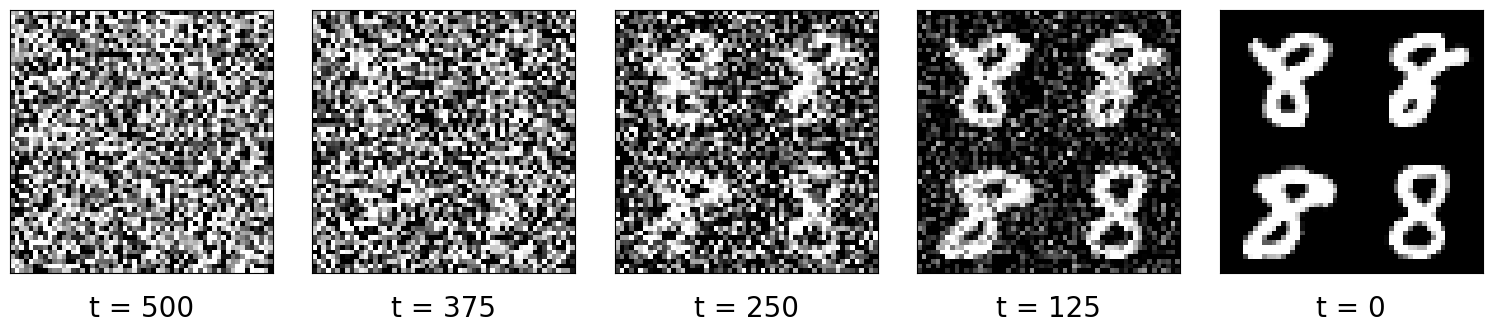

In [34]:
import matplotlib.pyplot as plt

n = len(images)

fig, axes = plt.subplots(1, n, figsize=(3.8*n, 4.5))

if n == 1:
    axes = [axes]

for i, (ax, img) in enumerate(zip(axes, images)):
    ax.imshow(img, cmap="gray")

    # Remove ticks but keep clean frame spacing
    ax.set_xticks([])
    ax.set_yticks([])

    # Caption under plot
    ax.set_title(f"t = {([500, 375, 250, 125, 0])[i]}", y=-0.2, fontsize=20)

# Better spacing between plots + room for captions
plt.subplots_adjust(wspace=0.15, bottom=0.25)

plt.show()

In [35]:
n_samples = 4
s = 0
final = []

xt_hist = []

xt = torch.randn(n_samples, 1, img_size, img_size).to(device)
xt_hist.append(xt)

for i in reversed(range(timesteps)):
    t = torch.tensor([i] * n_samples, device=device)
    t_float = t.float() / timesteps
    
    with torch.no_grad():
        eps_pred = model(xt, t_float)
    
    alpha_t = alpha[i]
    alpha_bar_t = alpha_bar[i]
    beta_t = beta[i]

    mean = (xt - ((1 - alpha_t) / torch.sqrt(1 - alpha_bar_t)) * eps_pred) / torch.sqrt(alpha_t)

    if i in [375, 250, 125]:
        xt_hist.append(xt)

    xt_for_grad = xt.detach().requires_grad_(True)

    xt_flat = xt_for_grad.reshape(-1, 784)

    xt_centred = xt_flat - mean_pca.cuda()
    xt_pca = xt_centred @ components.cuda()
    
    ratio = xt_pca @ theta
    log_r = torch.log(torch.clamp(ratio, min=1e-8))
    
    guide_score = torch.autograd.grad(log_r.sum(), xt_for_grad)[0]
    
    mean = mean + s * beta_t * guide_score
    
    if i > 0:
        noise = torch.randn_like(xt)
        xt = mean + torch.sqrt(beta_t) * noise
    else:
        xt = mean

xt = xt.cpu()

xt_hist.append(xt)

In [36]:
images = []
for xt in xt_hist:
    img = torch.tensor([])
    for row in xt.cpu().split(2):
        img_row = torch.concat([row[i] for i in range(row.shape[0])], dim =1).cpu()
        img = torch.cat([img, img_row], dim=-1)
    images.append((img.permute(1,2,0) * 0.5 + 0.5).clamp(0, 1))

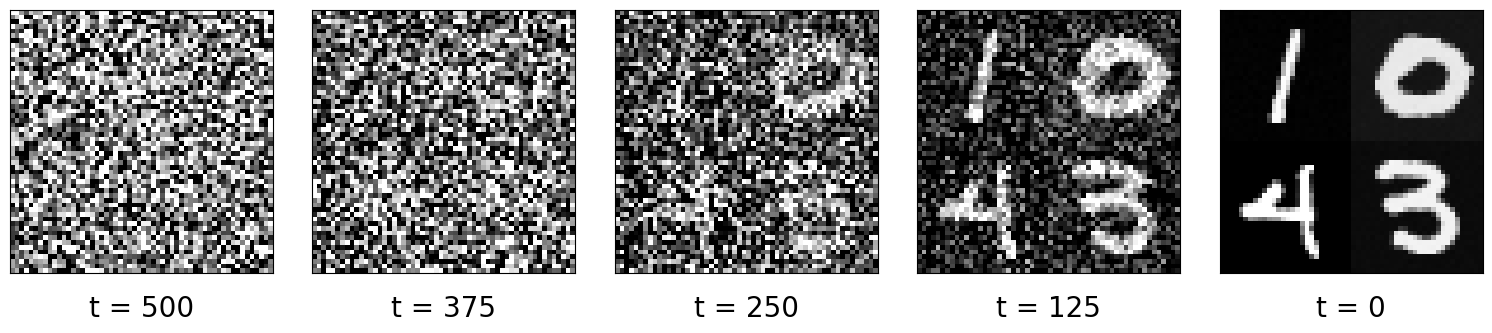

In [37]:
import matplotlib.pyplot as plt

n = len(images)

fig, axes = plt.subplots(1, n, figsize=(3.8*n, 4.5))

if n == 1:
    axes = [axes]

for i, (ax, img) in enumerate(zip(axes, images)):
    ax.imshow(img, cmap="gray")

    # Remove ticks but keep clean frame spacing
    ax.set_xticks([])
    ax.set_yticks([])

    # Caption under plot
    ax.set_title(f"t = {([500, 375, 250, 125, 0])[i]}", y=-0.2, fontsize=20)

# Better spacing between plots + room for captions
plt.subplots_adjust(wspace=0.15, bottom=0.25)

plt.show()